# llamaswap — full functionality test notebook

Runs every endpoint of the llamaswap proxy (default `http://localhost:11434`): health, registry, chat (streaming + JSON), embeddings, TTS across all backends (WAV/mp3/voices), ASR formats, image generation, music generation, Ollama compatibility, metrics/events, error paths, and admin endpoints.

Cells that load big models are marked **SLOW**.

In [16]:
import requests, json, time, base64
from IPython.display import Audio, Image as IPImage, display

BASE_URL = "http://localhost:11434"   # production container
API_KEY  = ""                        # set when LLAMASWAP_API_KEY is configured
HDRS     = ({"Authorization": f"Bearer {API_KEY}"} if API_KEY else {})

def api(method, path, expect_ok=True, **kw):
    kw.setdefault("timeout", 1800)
    r = requests.request(method, BASE_URL + path, headers=HDRS, **kw)
    if expect_ok:
        assert r.status_code == 200, f"{method} {path} -> {r.status_code}: {r.text[:400]}"
    return r

def show(obj, limit=600):
    s = json.dumps(obj, indent=2, default=str) if not isinstance(obj, str) else obj
    print(s if len(s) <= limit else s[:limit] + f"\n... ({len(s)} bytes total)")

## 1. Health overview

Every resident group: chat LLM, embedding, TTS/ASR, image, music — live states plus registry warnings/degraded conditions.

In [17]:
show(api("GET", "/health").json())

{
  "status": "ok",
  "current_model": {
    "state": "stopped",
    "model": null,
    "detail": ""
  },
  "embedding": {
    "state": "stopped",
    "model": "octen-embedding-0.6b",
    "port": 8102,
    "stopped_for_resources": false,
    "detail": ""
  },
  "audio": {
    "tts": {
      "role": "tts",
      "state": "stopped",
      "model": null,
      "detail": ""
    },
    "asr": {
      "role": "asr",
      "state": "ready",
      "model": "whisper-asr",
      "port": 8105,
      "detail": "",
      "idle_seconds": 80.0,
      "idle_unload_seconds": 300.0
    }
  },
  "image": {
    "
... (840 bytes total)


## 2. Registry: `/v1/models` (OpenAI-style + live state) and `/v1/registry/info`

In [18]:
models = api("GET", "/v1/models").json()["data"]
for m in models:
    print(f"{m['id']:22s} role={m['role']:10s} loaded={m['loaded']} family={m['family']}")

info = api("GET", "/v1/registry/info").json()
print("\nroles:", info["roles"])
print("smallest chat LLM (VRAM-guard pivot):", info["smallest_llm"])
print("llm_vram_mb:", info["llm_vram_mb"])

bonsai-27b             role=llm        loaded=False family=qwen
flux-schnell           role=image      loaded=False family=flux
minimax-music3         role=music      loaded=False family=minimax_music3
nemotron-asr-stream    role=asr        loaded=False family=nemotron_asr
nemotron-asr           role=asr        loaded=False family=nemotron_asr
octen-embedding-0.6b   role=embedding  loaded=False family=octen
outetts                role=tts        loaded=False family=outetts
qwen-image-2.1-uc      role=image      loaded=False family=qwen_image
qwen3-asr-stream       role=asr        loaded=False family=qwen3_asr
qwen3-asr              role=asr        loaded=False family=qwen3_asr
qwen3-tts              role=tts        loaded=False family=qwen3_tts
qwen3.5-9b             role=llm        loaded=False family=qwen
qwen3.6-35b-vision     role=llm        loaded=False family=qwen
qwen3.6-35b            role=llm        loaded=False family=qwen
qwen3.8-27b-exl3       role=llm        loaded=False f

## 3. Single-model detail + unknown-model error path

In [19]:
show(api("GET", "/v1/models/qwen3.5-9b").json())

r = api("GET", "/v1/models/does-not-exist", expect_ok=False)
print("unknown model ->", r.status_code, r.json()["error"]["message"])

{
  "id": "qwen3.5-9b",
  "object": "model",
  "created": 0,
  "owned_by": "llamaswap",
  "description": "Qwen3.5-9B Multimodal dense, Q8_0 quant, Image & Text chat",
  "role": "llm",
  "context_length": 32000,
  "family": "qwen",
  "capabilities": [
    "chat",
    "vision"
  ],
  "vram_gb": null,
  "gpu": null,
  "state": "stopped",
  "loaded": false
}
unknown model -> 404 model 'does-not-exist' not found


## 4. Chat: `/v1/chat/completions` (**SLOW**)

First request boots the chat `llama-server`; per the VRAM guards a chat request stops the image and music servers (and TTS/ASR for a big LLM).

In [20]:
t0 = time.time()
msg = api("POST", "/v1/chat/completions", json={
    "model": "qwen3.5-9b",
    "messages": [{"role": "user", "content": "Reply with exactly: llamaswap works"}],
}).json()
print(f"{time.time()-t0:.1f}s (includes ~load time on first request)")
print("reply:", msg["choices"][0]["message"]["content"].strip())
print("served as model:", msg["model"])

29.0s (includes ~load time on first request)
reply: llamaswap works
served as model: qwen3.5-9b


## 4b. OpenAI Responses API `/v1/responses` — passthrough to llama-server

In [21]:
r = api("POST", "/v1/responses", json={
    "model": "qwen3.5-9b",
    "input": "Reply with exactly one word: works",
    "max_output_tokens": 256,
})
print("status:", r.status_code)
out = r.json()
print("output_text:", str(out.get("output_text") or out)[:200])

status: 200
output_text: {'completed_at': 1792313870, 'created_at': 1792313870, 'id': 'resp_gHh7q7I2HYaugvplPXhIoUzJvueht6xZ', 'model': 'qwen3.5-9b', 'object': 'response', 'output': [{'id': 'rs_7b15Ffv2lBJmij98n6EzWJdVbG8Z22E


## 5. Chat streaming (SSE relay) + legacy `/v1/completions`

`qwen3.5-9b` is a thinking model: `reasoning_content` deltas stream first, `content` appears after.

In [22]:
r = api("POST", "/v1/chat/completions", stream=True, json={
    "model": "qwen3.5-9b",
    "messages": [{"role": "user", "content": "Count from 1 to 5, digits only."}],
    "max_tokens": 512, "stream": True,   # thinking models spend EarlyBudget: give the reply room
})
chunks = 0
content = ""
reasoning = ""
for line in r.iter_lines(decode_unicode=True):
    if line.startswith("data: ") and "[DONE]" not in line:
        chunks += 1
        delta = json.loads(line[6:])["choices"][0]["delta"]
        content += delta.get("content") or ""
        reasoning += delta.get("reasoning_content") or ""
print(f"received {chunks} SSE chunks")
print("streamed reply:", (content or "(no content -- model spent all tokens reasoning)").strip())
if reasoning:
    print("reasoning captured:", len(reasoning), "chars")

received 514 SSE chunks
streamed reply: (no content -- model spent all tokens reasoning)
reasoning captured: 1846 chars


In [23]:
c = api("POST", "/v1/completions", json={
    "model": "qwen3.5-9b", "prompt": "One word for a very fast turtle: ", "max_tokens": 4,
}).json()
print("legacy /v1/completions:", c["choices"][0]["text"].strip())

legacy /v1/completions: 1) ___________


## 6. Embeddings — served by the persistent embedding server (`octen-embedding-0.6b`); never swaps the chat LLM

In [24]:
emb = api("POST", "/v1/embeddings", json={"model": "octen-embedding-0.6b", "input": "hello world"}).json()
vec = emb["data"][0]["embedding"]
print("dims:", len(vec), "| head:", [round(x, 4) for x in vec[:3]])

dims: 1024 | head: [-0.0143, 0.0204, -0.0105]


## 7. TTS voices — per-backend presets (**SLOW** first call boots a TTS server)

`?model=` selects/boots a backend: supertonic-3 reports built-ins F1..F5/M1..M5; outetts and qwen3-tts are clone models (empty now — lists grow with cached clone voices).

In [25]:
for model in ("outetts", "qwen3-tts", "supertonic-3"):
    print(f"voices[{model:12s}]", api("GET", f"/v1/audio/voices?model={model}").json()["voices"])

voices[outetts     ] []
voices[qwen3-tts   ] []
voices[supertonic-3] ['F1', 'F2', 'F3', 'F4', 'F5', 'M1', 'M2', 'M3', 'M4', 'M5']


## 8. TTS `/v1/audio/speech`: outetts (clone reference injected) (**SLOW**)

llamaswap injects the backend's configured `meta.reference_voice` for clone-capable models — a plain OpenAI `input` is all a client sends.

In [26]:
t0 = time.time()
wav = api("POST", "/v1/audio/speech", json={
    "model": "outetts",
    "input": "Greetings from llamaswap, testing the OuteTTS backend with its configured reference voice.",
}).content
open("/tmp/tts-outetts.wav", "wb").write(wav)
print(f"{len(wav)} bytes of wav in {time.time()-t0:.1f}s; magic bytes:", wav[:4])
display(Audio("/tmp/tts-outetts.wav"))

248988 bytes of wav in 13.2s; magic bytes: b'RIFF'


## 8b. TTS: qwen3-tts (clone model, its own reference) (**SLOW**)

In [27]:
t0 = time.time()
wav = api("POST", "/v1/audio/speech", json={
    "model": "qwen3-tts",
    "input": "Hello from a cloned voice!",
    "response_format": "mp3",
}).content
open("/tmp/tts-qwen3tts.mp3", "wb").write(wav)
print(f"{len(wav)} bytes mp3 in {time.time()-t0:.1f}s | magic:", wav[:3], "(ID3/0xff = mp3 ok)")
display(Audio("/tmp/tts-qwen3tts.mp3"))

7340 bytes mp3 in 9.8s | magic: b'ID3' (ID3/0xff = mp3 ok)


## 8c. TTS: supertonic-3 (built-in preset voices) (**SLOW**)

Preset voices F1..F5 / M1..M5; see section 7.

In [28]:
t0 = time.time()
wav = api("POST", "/v1/audio/speech", json={
    "model": "supertonic-3", "input": "Testing llamaswap text to speech.", "voice": "M2",
}).content
open("/tmp/tts-supertonic.wav", "wb").write(wav)
print(f"{len(wav)} bytes of wav in {time.time()-t0:.1f}s")

mp3 = api("POST", "/v1/audio/speech", json={
    "model": "supertonic-3", "input": "Second short sentence for the mp3 path.", "voice": "F1",
    "response_format": "mp3"}).content
print("mp3 bytes:", len(mp3), "| magic:", mp3[:3])
display(Audio("/tmp/tts-supertonic.wav"))

214776 bytes of wav in 6.3s
mp3 bytes: 25330 | magic: b'ID3'


## 8d. `/v1/audio/speech/stream` — live chunked audio (**SLOW**)

`supertonic-3-stream` (same weights as supertonic-3) runs audio.cpp in `mode: streaming`
so it answers `/v1/audio/speech` with OpenAI-shaped SSE: `speech.audio.delta` events
(base64 PCM16 @ 44.1 kHz mono) → `speech.audio.done` → `[DONE]`. llamaswap relays
deltas unbuffered. Offline TTS models refuse streaming — the second part shows the
exact error envelope they return.

In [29]:
resse = api("POST", "/v1/audio/speech/stream", stream=True, json={
    "model": "supertonic-3-stream",
    "input": "First sentence arrives early. Second chunk follows. Third lands later.",
    "voice": "F3",
})
pcm = b""; deltas = 0; done = None; buf = b""
for chunk in resse.iter_content(chunk_size=None, decode_unicode=False):
    buf += chunk
    while b"\n" in buf:
        line, buf = buf.split(b"\n", 1)
        line = line.strip()
        if not line.startswith(b"data: "):
            continue
        payload = line[6:]
        if payload == b"[DONE]":
            break
        obj = json.loads(payload)
        if obj.get("type") == "speech.audio.delta":
            deltas += 1
            pcm += base64.b64decode(obj["audio"])
        elif obj.get("type") == "speech.audio.done":
            done = obj
if deltas:
    import wave
    w = wave.open("/tmp/stream.wav", "wb")
    w.setnchannels(1); w.setsampwidth(2); w.setframerate(44100)
    w.writeframes(pcm); w.close()
    print(f"{resse.status_code} | {deltas} delta events | {len(pcm)/2/44100:.2f}s audio | done: {bool(done)}")
    display(Audio("/tmp/stream.wav"))
else:
    print("no deltas; body head:", (pcm or b"")[:200])

# offline model: meaningful refusal, not a silent failure
roff = api("POST", "/v1/audio/speech/stream", expect_ok=False,
           json={"model": "supertonic-3", "input": "Hello"})
print("offline model on stream endpoint ->", roff.status_code)
print(str(roff.json())[:200])

200 | 1 delta events | 5.67s audio | done: True


offline model on stream endpoint -> 200
{'error': {'message': {'error': {'message': 'speech streaming requires a model configured with mode=streaming', 'type': 'server_error'}}}}


## 9. ASR `/v1/audio/transcriptions` (**SLOW**) — multipart round-trip on the TTS output

Tests the proxy's response-format normalizer and backend switching via the `model` field (whisper-asr / qwen3-asr / nemotron-asr).

In [30]:
for model, fmt in [("qwen3-asr", "json"), ("whisper-asr", "verbose_json"),
                  ("whisper-asr", "srt"), ("whisper-asr", "vtt"),
                  ("qwen3-asr", "text")]:
    with open("/tmp/tts-supertonic.wav", "rb") as fh:
        r = api("POST", "/v1/audio/transcriptions", expect_ok=False,
                files={"file": ("tts.wav", fh, "audio/wav")},
                data={"model": model, "response_format": fmt})
    body = r.text[:150].replace(chr(10), " | ")
    print(f"{model} fmt={fmt:12s} -> {r.status_code}: {body}")


qwen3-asr fmt=json         -> 200: {"text":"Testing lama swap text to speech.","timing":{"wall_ms":272.946,"audio_duration_ms":2434.6,"rtf":0.112111}}
whisper-asr fmt=verbose_json -> 200: {"task":"transcribe","language":"english","duration":2.4346249103546143,"text":" Testing llama swap text to speech.\n","segments":[{"id":0,"text":" Te
whisper-asr fmt=srt          -> 200: 1 | 00:00:00,000 --> 00:00:02,000 |  Testing llama swap text to speech. |  | 
whisper-asr fmt=vtt          -> 200: WEBVTT |  | 00:00:00.000 --> 00:00:02.000 |  Testing llama swap text to speech. |  | 
qwen3-asr fmt=text         -> 200: Testing lama swap text to speech. | 


## 9b. `/v1/audio/translations` — OpenAI "transcribe + translate to English"

`whisper-asr` declares `meta.translation_target`: the proxy rewrites the request onto whisper.cpp's transcription route with a `translate` flag. Backends without translation get a clear 400.

In [31]:
with open("/tmp/tts-supertonic.wav", "rb") as fh:
    r = api("POST", "/v1/audio/translations", expect_ok=False,
            files={"file": ("tts.wav", fh, "audio/wav")},
            data={"model": "whisper-asr"})
print("whisper-asr ->", r.status_code, ":", r.text[:150].replace(chr(10), " | "))

with open("/tmp/tts-supertonic.wav", "rb") as fh:
    r = api("POST", "/v1/audio/translations", expect_ok=False,
            files={"file": ("tts.wav", fh, "audio/wav")},
            data={"model": "qwen3-asr"})
print("qwen3-asr  ->", r.status_code, r.json()["error"]["message"][:110])

whisper-asr -> 200 : {"text":" Testing llama swap text to speech.\n"}
qwen3-asr  -> 400 model 'qwen3-asr' does not support translation (backend 'qwen3_asr' has no translate-capable route)


## 9c. `/v1/audio/transcriptions/stream` — live transcription SSE (**SLOW**)

`nemotron-asr-stream` and `qwen3-asr-stream` (same weights as their offline siblings) run audio.cpp
in `mode: streaming` and emit OpenAI-shaped `transcript.text.delta` → `transcript.text.done` events
that llamaswap relays unbuffered. Multipart-only backends (whisper.cpp) are refused with a clear 400.

In [32]:
for model in ("nemotron-asr-stream", "qwen3-asr-stream", "whisper-asr"):
    files = {"file": ("t.wav", open("/tmp/tts-supertonic.wav", "rb"), "audio/wav")}
    rss = api("POST", "/v1/audio/transcriptions/stream", expect_ok=False, stream=True,
              files=files, data={"model": model})
    buf = b""; deltas = 0; text = ""; done = False
    for chunk in rss.iter_content(chunk_size=None, decode_unicode=False):
        buf += chunk
        while b"\n" in buf:
            line, buf = buf.split(b"\n", 1)
            line = line.strip()
            if not line.startswith(b"data: "):
                continue
            payload = line[6:]
            if payload == b"[DONE]":
                done = True
                break
            try:
                obj = json.loads(payload)
            except ValueError:
                continue
            if obj.get("type") == "transcript.text.delta":
                deltas += 1
            if isinstance(obj.get("segment"), dict):
                text += obj["segment"].get("text", "")
    tip = deltas if deltas else "no SSE"
    print(f"{model:22s} -> {rss.status_code} | deltas: {tip} | done: {done} | text: {text.strip()[:60]}")


nemotron-asr-stream    -> 200 | deltas: 16 | done: True | text: 
qwen3-asr-stream       -> 200 | deltas: 1 | done: True | text: 
whisper-asr            -> 400 | deltas: no SSE | done: False | text: 


## 10. Ollama compat surface: `/api/tags` + `/api/ps`

In [33]:
tags = api("GET", "/api/tags").json()["models"]
print("total listed:", len(tags), "| first:", tags[0]["name"], tags[0]["details"]["parameter_size"])

ps = api("GET", "/api/ps").json()["models"]
for p in ps:
    print("resident:", p["name"], p["details"]["quantization_level"] or "")

total listed: 19 | first: bonsai-27b 27B
resident: qwen3.5-9b 
resident: octen-embedding-0.6b 
resident: supertonic-3 
resident: whisper-asr 


## 11. Metrics (Prometheus text) + events feed

In [34]:
m = api("GET", "/metrics").text
interesting = [l for l in m.splitlines()
               if l.startswith("llamaswap_") and not l.startswith("#")]
print("\n".join(interesting[:10]))

r = api("GET", "/v1/events", stream=True)
print("\nevents feed status:", r.status_code, "(SSE open ok)")
r.close()

llamaswap_model_loads_total{role="asr",model="nemotron-asr-stream"} 3
llamaswap_model_loads_total{role="asr",model="qwen3-asr"} 3
llamaswap_model_loads_total{role="asr",model="qwen3-asr-stream"} 3
llamaswap_model_loads_total{role="asr",model="whisper-asr"} 4
llamaswap_model_loads_total{role="embedding",model="octen-embedding-0.6b"} 1
llamaswap_model_loads_total{role="llm",model="qwen3.5-9b"} 1
llamaswap_model_loads_total{role="tts",model="outetts"} 2
llamaswap_model_loads_total{role="tts",model="qwen3-tts"} 2
llamaswap_model_loads_total{role="tts",model="supertonic-3"} 3
llamaswap_model_loads_total{role="tts",model="supertonic-3-stream"} 1

events feed status: 200 (SSE open ok)


## 12. Image generation `/v1/images/generations` (**SLOW ~3-5 min**)

Boots the sd-server (Qwen-Image 2.1); `LLAMASWAP_UNLOAD_ON_IMAGE` stops chat + audio + embedding first.

844334 bytes PNG in 28.1s


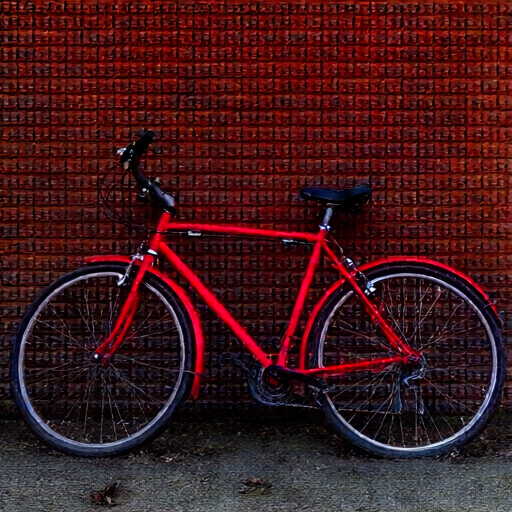

In [35]:
t0 = time.time()
img = api("POST", "/v1/images/generations", json={
    "model": "qwen-image-2.1-uc",
    "prompt": "a red bicycle leaning on a brick wall",
    "size": "512x512", "n": 1,
}).json()
png = base64.b64decode(img["data"][0]["b64_json"])
open("/tmp/test-image.png", "wb").write(png)
print(f"{len(png)} bytes PNG in {time.time()-t0:.1f}s")
display(IPImage("/tmp/test-image.png"))

## 12b. `/v1/images/edits` — real multipart image edit (**SLOW**)

The OpenAI edits dialect is multipart/form-data with the source image plus prompt. Qwen-Image-2.1 editing works out of the box: the safetensors Qwen3-VL-8B text encoder ships full vision weights (no `--llm_vision` mmproj needed — that is only required when the text encoder is a GGUF).

In [ ]:
files = {"image": ("bicycle.png", open("/tmp/test-image.png", "rb"), "image/png")}
t0 = time.time()
out = api("POST", "/v1/images/edits",
          data={"model": "qwen-image-2.1-uc", "prompt": "make the bicycle blue", "size": "512x512"},
          files=files).json()
png = base64.b64decode(out["data"][0]["b64_json"])
open("/tmp/edit-image.png", "wb").write(png)
print(f"edited image: {len(png)} bytes PNG in {time.time()-t0:.1f}s")
print("before -> after:")
display(IPImage("/tmp/test-image.png"))
display(IPImage("/tmp/edit-image.png"))


## 13. Music generation `/v1/audio/music` (**SLOW ~1-2 min**)

`minimax-music3` via audio.cpp. Whole-GPU workload: chat/TTS/ASR/embedding/image are unloaded before it loads.

In [37]:
t0 = time.time()
song = api("POST", "/v1/audio/music", json={
    "model": "minimax-music3",
    "input": "A bright pop rock song with clean drums and a clear male vocal.",
    "lyrics": "[verse] City lights are shining low.\n[chorus] Turn it up and let it fly.",
    "duration": 10,
}).content
open("/tmp/test-song.wav", "wb").write(song)
print(f"{len(song)} bytes wav in {time.time()-t0:.1f}s | magic:", song[:4])
display(Audio("/tmp/test-song.wav"))

3530796 bytes wav in 65.0s | magic: b'RIFF'


## 14. Music endpoint error paths (and wrong-role rejection)

In [38]:
r = api("POST", "/v1/audio/music", json={"model": "minimax-music3", "lyrics": "no caption!"}, expect_ok=False)
print("missing caption ->", r.status_code, str(r.json())[:150])

r = api("POST", "/v1/audio/music", json={"model": "supertonic-3", "input": "x"}, expect_ok=False)
print("wrong role     ->", r.status_code, r.json()["error"]["message"][:100])

r = api("POST", "/v1/audio/music", json={"model": "no-such-model", "input": "x"}, expect_ok=False)
print("unknown model  ->", r.status_code, str(r.json())[:120])

missing caption -> 500 {'error': {'message': 'MiniMax Music 3 requires non-empty text input', 'type': 'server_error'}}
wrong role     -> 400 model 'supertonic-3' is not a music model (role: tts)
unknown model  -> 404 {'error': {'message': "model 'no-such-model' not found; available: bonsai-27b, flux-schnell, minimax-music3, nemotron-as


## 15. Admin endpoints: unload, reset, registry reload

In [39]:
print("unload chat ->", api("POST", "/v1/models/qwen3.5-9b/unload").status_code)

snapshot = api("POST", "/v1/reset").json()
print("post-reset:", snapshot["music"]["state"], "| image:", snapshot["image"]["state"],
      "| chat:", snapshot["current_model"]["state"])

prez = api("POST", "/v1/registry/reload").json()
print("reload ->", prez["reloaded"], "| models:", len(prez["models"]), "| warnings:", prez["warnings"])

unload chat -> 200
post-reset: stopped | image: stopped | chat: stopped
reload -> True | models: 19 | warnings: []


## 15b. Preload/warm via `/v1/models/{model}/load` (**SLOW**)

In [40]:
snap = api("POST", "/v1/models/supertonic-3/load").json()
print("preload state:", snap["audio"]["tts"])

preload state: {'role': 'tts', 'state': 'ready', 'model': 'supertonic-3', 'port': 8108, 'detail': '', 'idle_seconds': 7.0, 'idle_unload_seconds': 300.0}


### X-Pin-Seconds — suppress idle unload for a request

In [41]:
r = requests.post(BASE_URL + "/v1/chat/completions", headers={**HDRS, "X-Pin-Seconds": "30"},
                  json={"model": "qwen3.5-9b", "messages": [{"role": "user", "content": "hi"}], "max_tokens": 4})
print("pin request ->", r.status_code, "| +30s idle credit accepted")
# then release via reset at the end


pin request -> 200 | +30s idle credit accepted


## 16. VRAM guard behavior: audio blocked while a big LLM holds the GPU (**SLOW**)

A "big" LLM = any chat model other than the smallest weights file (`qwen3.5-9b`). While one is loaded, TTS/ASR requests are refused with `409` — the only endpoint that returns 409.

In [42]:
t0 = time.time()
msg = api("POST", "/v1/chat/completions", json={
    "model": "qwen3.8-27b-ridge",
    "messages": [{"role": "user", "content": "hi"}], "max_tokens": 4,
}).json()
print(f"big LLM loaded ({time.time()-t0:.0f}s incl. load); chat manager:",
      api("GET", "/health").json()["current_model"]["model"])

r = api("POST", "/v1/audio/speech", expect_ok=False, json={
    "model": "supertonic-3", "input": "should be refused", "voice": "F1"})
print("TTS while big LLM loaded ->", r.status_code, "|", r.json()["error"]["message"][:110])

t0 = time.time()
msg = api("POST", "/v1/chat/completions", json={
    "model": "qwen3.5-9b",
    "messages": [{"role": "user", "content": "hi"}], "max_tokens": 4,
}).json()
print(f"switched to small LLM afterwards ({time.time()-t0:.0f}s swap)")

r = api("POST", "/v1/audio/speech", json={
    "model": "supertonic-3", "input": "now allowed", "voice": "F2"})
print("TTS after small LLM swap ->", r.status_code, len(r.content), "bytes")

big LLM loaded (54s incl. load); chat manager: qwen3.8-27b-ridge
TTS while big LLM loaded -> 409 | audio tts is blocked while big chat model 'qwen3.8-27b-ridge' is loaded; unload it (or wait for idle unload) b


AssertionError: POST /v1/chat/completions -> 503: {"error":{"message":"backend llama-server is not reachable"}}

In [ ]:
snap = api("POST", "/v1/reset").json()
print("final reset -> everything stopped:")
print("chat:", snap["current_model"]["state"], "| tts:", snap["audio"]["tts"]["state"],
      "| image:", snap["image"]["state"], "| music:", snap["music"]["state"])
